# Garment order model training and comparison

This is the **single notebook** version of `model_features.py`, `neural_models.py`, `train_model.py`, and `plot_model_comparison.py`. All Python code is included in cells below; the notebook does not import those project scripts or call `compare_models.py`.

Run cells from top to bottom. It trains the N1 and N2 classifiers, compares cost regressors, saves selected models and metrics under `models/`, saves PNG/SVG score charts under `plots/`, then displays rankings and charts. It still reads the project CSV data from `data/` and requires the packages listed in `requirements.txt`.

In [13]:
# This notebook contains the feature, neural model, training, and plotting code inline.
# Run from the project root; CSV inputs are read from data/.
from pathlib import Path
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
print(f"Project folder: {PROJECT_ROOT}")
print("Expected input files: data/orders.csv, data/allocations.csv, data/interventions.csv")

Project folder: d:\Freelance\Nadee\garment_order_system
Expected input files: data/orders.csv, data/allocations.csv, data/interventions.csv


## Feature engineering (from model_features.py)

In [14]:
"""Shared feature engineering used during training and live order prediction."""
SCENARIO_ENCODING = {
    name: index
    for index, name in enumerate(
        ["Current", "Extra_Workers", "Hybrid", "Machine_Adjust", "Outsourcing", "Overtime"]
    )
}
STYLE_ENCODING = {"Hoodie": 0, "Jacket": 1, "Legging": 2, "Polo": 3, "T-Shirt": 4}
PRIORITY_ENCODING = {"Low": 0, "Normal": 1, "High": 2}
STYLE_CAPACITY_FACTOR = {"Polo": 1.00, "T-Shirt": 1.02, "Hoodie": 0.94,
                         "Legging": 0.98, "Jacket": 0.92}
PRIORITY_CAPACITY_FACTOR = {"Low": 1.04, "Normal": 1.00, "High": 0.90}


def build_factory_profile(orders, allocations):
    """Estimate typical order and factory values from the available records."""
    per_order = allocations.groupby("order_id").agg(
        n_conflicts=("conflict_flag", "sum"),
        avg_worker_eff=("actual_efficiency", "mean"),
    )
    return {
        "smv": float(orders["required_smv_total"].median()),
        "unit_value": float((orders["order_value"] / orders["order_quantity"]).median()),
        "typical_workers": float(orders["n_available_workers"].median()),
        "typical_shifts": float(orders["n_shifts"].median()),
        "shift_hours": float(orders["shift_hours"].median()),
        "capacity_efficiency": float(orders["avg_worker_efficiency"].median()),
        "n_conflicts": float(per_order["n_conflicts"].median()),
        "avg_worker_eff": float(per_order["avg_worker_eff"].median()),
    }


def build_order_features(quantity, handover_days, smv, order_value, style, priority, profile):
    """Build matching features from quantity, days, SMV, value, style and priority."""
    quantity = float(quantity)
    handover_days = max(float(handover_days), 1.0)
    smv = float(smv)
    order_value = float(order_value)
    workload = quantity * smv
    daily_capacity = (
        profile["typical_workers"]
        * profile["shift_hours"]
        * 60
        * profile["capacity_efficiency"] / 100
        * profile["typical_shifts"]
    )
    return {
        "order_quantity": quantity,
        "handover_days": handover_days,
        "required_smv_total": smv,
        "order_value": order_value,
        "style_enc": STYLE_ENCODING[style],
        "priority_enc": PRIORITY_ENCODING[priority],
        "unit_value": order_value / quantity,
        "estimated_workload_min": workload,
        "estimated_workload_per_day": workload / handover_days,
        "capacity_ratio": (
            daily_capacity * handover_days / max(workload, 1)
            * STYLE_CAPACITY_FACTOR[style]
            * PRIORITY_CAPACITY_FACTOR[priority]
        ),
    }


def make_intervention_features(order_features, scenario, profile):
    """Append the factory-level and scenario features used by the N2 model."""
    row = {
        "scenario_enc": SCENARIO_ENCODING[scenario["scenario_type"]],
        "added_workers": float(scenario["added_workers"]),
        "overtime_hours": float(scenario["overtime_hours"]),
        "added_machines": float(scenario["added_machines"]),
        "outsourced_qty": float(scenario["outsourced_qty"]),
        "order_quantity": order_features["order_quantity"],
        "handover_days": order_features["handover_days"],
        "order_value": order_features["order_value"],
        "required_workload_min": order_features["estimated_workload_min"],
        "style_enc": order_features["style_enc"],
        "priority_enc": order_features["priority_enc"],
        "capacity_ratio": order_features["capacity_ratio"],
        "n_conflicts": profile["n_conflicts"],
        "avg_worker_eff": profile["avg_worker_eff"],
    }
    return row


## DNN, GANN, and GNN implementations (from neural_models.py)

In [15]:
"""Scikit-learn-compatible neural models used in model comparison.

The graph classifier builds a feature-similarity graph over training examples.
Each row is a node; edges connect the nearest training rows, and a mean
neighbour message is concatenated with each node's own features.
"""
import numpy as np
import tensorflow as tf
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler


class TensorFlowDNNClassifier(ClassifierMixin, BaseEstimator):
    """Dense neural classifier implemented with TensorFlow's Keras API."""

    def __init__(self, hidden_layer_sizes=(128, 64, 32), dropout=0.25,
                 learning_rate=0.001, epochs=100, batch_size=128, patience=8,
                 random_state=42):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        self.classes_ = np.unique(y.astype(int))
        self.scaler_ = StandardScaler().fit(X)
        X_scaled = self.scaler_.transform(X).astype(np.float32)

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(self.random_state)
        layers = [tf.keras.layers.Input(shape=(X_scaled.shape[1],))]
        for width in self.hidden_layer_sizes:
            layers.append(tf.keras.layers.Dense(width, activation="relu"))
            if self.dropout:
                layers.append(tf.keras.layers.Dropout(self.dropout))
        layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
        self.keras_model_ = tf.keras.Sequential(layers)
        self.keras_model_.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=self.learning_rate),
            loss="binary_crossentropy",
            metrics=["accuracy"],
        )
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=self.patience, restore_best_weights=True
        )
        self.history_ = self.keras_model_.fit(
            X_scaled, y,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            callbacks=[early_stopping],
            verbose=0,
        ).history
        return self

    def predict_proba(self, X):
        X_scaled = self.scaler_.transform(np.asarray(X, dtype=np.float32))
        positive = self.keras_model_.predict(X_scaled, verbose=0).reshape(-1)
        return np.column_stack([1.0 - positive, positive])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class GANNClassifier(ClassifierMixin, BaseEstimator):
    """Genetic-algorithm search over MLP architectures and learning settings."""

    def __init__(self, population_size=4, generations=2, max_iter=140,
                 random_state=42):
        self.population_size = population_size
        self.generations = generations
        self.max_iter = max_iter
        self.random_state = random_state

    def _model(self, chromosome, seed):
        hidden, alpha, learning_rate = chromosome
        return MLPClassifier(
            hidden_layer_sizes=hidden,
            alpha=alpha,
            learning_rate_init=learning_rate,
            max_iter=self.max_iter,
            early_stopping=True,
            validation_fraction=0.12,
            n_iter_no_change=12,
            random_state=seed,
        )

    @staticmethod
    def _score(model, X, y):
        probabilities = model.predict_proba(X)[:, 1]
        return brier_score_loss(y, probabilities)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.unique(y)
        rng = np.random.RandomState(self.random_state)
        x_fit, x_valid, y_fit, y_valid = train_test_split(
            X, y, test_size=0.2, random_state=self.random_state, stratify=y
        )

        hidden_choices = [(64, 32), (96, 48), (64, 32, 16), (128, 64)]
        alpha_choices = [0.0001, 0.001, 0.01]
        learning_rate_choices = [0.001, 0.003, 0.01]

        def random_chromosome():
            return (
                hidden_choices[rng.randint(len(hidden_choices))],
                alpha_choices[rng.randint(len(alpha_choices))],
                learning_rate_choices[rng.randint(len(learning_rate_choices))],
            )

        population = [random_chromosome() for _ in range(self.population_size)]
        fitness = {}
        for generation in range(self.generations):
            for chromosome in population:
                if chromosome not in fitness:
                    candidate = self._model(chromosome, self.random_state + generation)
                    candidate.fit(x_fit, y_fit)
                    fitness[chromosome] = self._score(candidate, x_valid, y_valid)
            ranked = sorted(population, key=lambda gene: fitness[gene])
            if generation + 1 < self.generations:
                parents = ranked[:max(2, len(ranked) // 2)]
                next_population = parents[:]
                while len(next_population) < self.population_size:
                    first = parents[rng.randint(len(parents))]
                    second = parents[rng.randint(len(parents))]
                    child = [first[0], second[1], first[2]]
                    if rng.rand() < 0.4:
                        child[0] = hidden_choices[rng.randint(len(hidden_choices))]
                    if rng.rand() < 0.4:
                        child[1] = alpha_choices[rng.randint(len(alpha_choices))]
                    if rng.rand() < 0.4:
                        child[2] = learning_rate_choices[rng.randint(len(learning_rate_choices))]
                    next_population.append(tuple(child))
                population = next_population

        self.best_config_ = min(fitness, key=fitness.get)
        self.model_ = self._model(self.best_config_, self.random_state)
        self.model_.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))

    def predict(self, X):
        return self.model_.predict(np.asarray(X, dtype=float))


class GraphNeuralNetworkClassifier(ClassifierMixin, BaseEstimator):
    """One-step graph message-passing classifier over feature-similar rows."""

    def __init__(self, n_neighbors=8, hidden_layer_sizes=(64, 32), max_iter=220,
                 random_state=42):
        self.n_neighbors = n_neighbors
        self.hidden_layer_sizes = hidden_layer_sizes
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.unique(y)
        self.scaler_ = StandardScaler().fit(X)
        self.X_train_ = self.scaler_.transform(X)
        count = min(self.n_neighbors + 1, len(self.X_train_))
        self.neighbors_ = NearestNeighbors(n_neighbors=count).fit(self.X_train_)
        indices = self.neighbors_.kneighbors(self.X_train_, return_distance=False)

        aggregate = np.zeros_like(self.X_train_)
        for row_index, row_neighbors in enumerate(indices):
            # Self-loops are excluded; the remaining neighbours send messages.
            selected = [idx for idx in row_neighbors if idx != row_index][:self.n_neighbors]
            if selected:
                aggregate[row_index] = self.X_train_[selected].mean(axis=0)
        graph_features = np.hstack([self.X_train_, aggregate])
        self.model_ = MLPClassifier(
            hidden_layer_sizes=self.hidden_layer_sizes,
            alpha=0.01,
            max_iter=self.max_iter,
            early_stopping=True,
            validation_fraction=0.12,
            random_state=self.random_state,
        )
        self.model_.fit(graph_features, y)
        return self

    def _features(self, X):
        X_scaled = self.scaler_.transform(np.asarray(X, dtype=float))
        indices = self.neighbors_.kneighbors(
            X_scaled, n_neighbors=min(self.n_neighbors, len(self.X_train_)),
            return_distance=False,
        )
        aggregate = self.X_train_[indices].mean(axis=1)
        return np.hstack([X_scaled, aggregate])

    def predict_proba(self, X):
        return self.model_.predict_proba(self._features(X))

    def predict(self, X):
        return self.model_.predict(self._features(X))


## Train and compare (from train_model.py)

N1 uses stratified five-fold CV. N2 and cost estimation group all scenarios belonging to one order in the same fold. Classifiers are ranked by Brier score (lower is better), then ROC-AUC. Cost regressors are selected by MAE (lower is better).

In [16]:
"""Train order-feasibility and intervention models from the project CSV data.

The N1 model is trained from the six order fields in the form and derived
workload/capacity features. Cross-validation scores are out-of-fold estimates;
the CSVs currently contain generated demo data.
"""
import json
import os
import warnings

import joblib
import pandas as pd
from sklearn.ensemble import (
    AdaBoostClassifier,
    AdaBoostRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42
os.makedirs("models", exist_ok=True)
warnings.filterwarnings("ignore", category=UserWarning)

orders = pd.read_csv("data/orders.csv")
allocations = pd.read_csv("data/allocations.csv")
scenarios = pd.read_csv("data/interventions.csv")
profile = build_factory_profile(orders, allocations)

N1_FEATURES = [
    "order_quantity", "handover_days", "required_smv_total", "order_value",
    "style_enc", "priority_enc", "unit_value", "estimated_workload_min",
    "estimated_workload_per_day", "capacity_ratio",
]


def classification_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "accuracy": round(float(accuracy_score(y_true, predictions)), 4),
        "precision": round(float(precision_score(y_true, predictions, zero_division=0)), 4),
        "recall": round(float(recall_score(y_true, predictions, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, predictions, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(y_true, probabilities)), 4),
        "brier_score": round(float(brier_score_loss(y_true, probabilities)), 4),
        "confusion_matrix": confusion_matrix(y_true, predictions, labels=[0, 1]).tolist(),
    }


def compare_classifiers(name, candidates, X, y, cv, groups=None):
    scores = {}
    for model_name, model in candidates.items():
        print(f"  Training {model_name}...", flush=True)
        kwargs = {"groups": groups} if groups is not None else {}
        probabilities = cross_val_predict(
            model, X, y, cv=cv, method="predict_proba", n_jobs=1, **kwargs
        )[:, 1]
        scores[model_name] = classification_metrics(y, probabilities)
    # Brier score rewards useful, well-calibrated probabilities; AUC breaks ties.
    winner = min(scores, key=lambda key: (scores[key]["brier_score"], -scores[key]["roc_auc"]))
    final_model = candidates[winner].fit(X, y)
    scores = dict(sorted(
        scores.items(), key=lambda item: (item[1]["brier_score"], -item[1]["roc_auc"])
    ))
    print(f"\n{name} comparison (sorted by Brier score, then ROC-AUC):")
    for model_name, metrics in scores.items():
        marker = "  <-- BEST" if model_name == winner else ""
        print(
            f"  {model_name:<30} Brier={metrics['brier_score']:.4f}  "
            f"ROC-AUC={metrics['roc_auc']:.4f}  F1={metrics['f1']:.4f}{marker}"
        )
    return winner, final_model, scores


def save_classifier_bundle(name, model, features, profile, output_path,
                           keras_path, extra=None):
    """Save sklearn models in joblib and Keras networks in native .keras format."""
    bundle = {
        "name": name,
        "features": features,
        "profile": profile,
        "training_signature": "six-order-inputs-v1",
    }
    if extra:
        bundle.update(extra)
    if isinstance(model, TensorFlowDNNClassifier):
        model.keras_model_.save(keras_path)
        bundle.update({
            "model": None,
            "type": "keras",
            "model_path": keras_path,
            "scaler": model.scaler_,
        })
    else:
        bundle.update({"model": model, "type": "sklearn"})
    joblib.dump(bundle, output_path)


# N1: use the six order details available in the form, plus workload and
# capacity features derived from those inputs and the factory profile.
X1 = pd.DataFrame(
    [
        build_order_features(
            row.order_quantity, row.handover_days, row.required_smv_total,
            row.order_value, row.style_id, row.priority, profile,
        )
        for row in orders.itertuples()
    ],
    columns=N1_FEATURES,
)
y1 = orders["on_time_flag"].astype(int).to_numpy()

n1_candidates = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=10, min_samples_leaf=8,
        n_jobs=-1, random_state=SEED,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=160, max_depth=12, min_samples_leaf=6,
        n_jobs=-1, random_state=SEED,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=12, class_weight="balanced", random_state=SEED,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.06, random_state=SEED,
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=140, max_leaf_nodes=15, l2_regularization=2.0,
        learning_rate=0.07, random_state=SEED,
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.05, random_state=SEED),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1)
    ),
    "DNN (TensorFlow/Keras)": TensorFlowDNNClassifier(random_state=SEED),
    "Genetic Algorithm Neural Network (GANN)": make_pipeline(
        StandardScaler(), GANNClassifier(population_size=4, generations=2,
                                         max_iter=100, random_state=SEED)
    ),
    "Graph Neural Network (GNN)": GraphNeuralNetworkClassifier(random_state=SEED),
    "Gaussian Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
}
n1_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
n1_name, n1_model, n1_metrics = compare_classifiers(
    "On-time model", n1_candidates, X1, y1, n1_cv
)

# Notebook plot: Keras learning curves from a dedicated train/validation split.
dnn_history_model = TensorFlowDNNClassifier(random_state=SEED).fit(X1, y1)
save_classifier_bundle(
    n1_name, n1_model, N1_FEATURES, profile,
    "models/best_n1_model.pkl", "models/best_n1_model.keras",
    extra={"user_inputs": ["order_quantity", "handover_days", "required_smv_total", "order_value", "style_id", "priority"]},
)

# N2: preserve scenario labels and costs, but build the order-level fields with
# the same inferred profile used at prediction time. Grouped folds keep all six
# scenarios for an order on the same side of each validation split.
order_features = {
    int(row.order_id): build_order_features(
        row.order_quantity, row.handover_days, row.required_smv_total,
        row.order_value, row.style_id, row.priority, profile,
    )
    for row in orders.itertuples()
}
n2_feature_rows = []
for scenario in scenarios.to_dict(orient="records"):
    inferred = order_features[int(scenario["order_id"])]
    n2_feature_rows.append(make_intervention_features(inferred, scenario, profile))

N2_FEATURES = [
    "scenario_enc", "added_workers", "overtime_hours", "added_machines",
    "outsourced_qty", "order_quantity", "handover_days", "order_value",
    "required_workload_min", "style_enc", "priority_enc", "capacity_ratio",
    "n_conflicts", "avg_worker_eff",
]
X2 = pd.DataFrame(n2_feature_rows, columns=N2_FEATURES)
y2 = scenarios["selected_flag"].astype(int).to_numpy()
groups = scenarios["order_id"].to_numpy()
n2_cv = GroupKFold(n_splits=5)
n2_candidates = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=14, min_samples_leaf=5,
        n_jobs=-1, random_state=SEED,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=140, max_depth=16, min_samples_leaf=4,
        n_jobs=-1, random_state=SEED,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=10, class_weight="balanced", random_state=SEED,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=2, learning_rate=0.06, random_state=SEED,
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=140, max_leaf_nodes=19, l2_regularization=2.0,
        learning_rate=0.07, random_state=SEED,
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.05, random_state=SEED),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1)
    ),
    "DNN (TensorFlow/Keras)": TensorFlowDNNClassifier(random_state=SEED),
    "Genetic Algorithm Neural Network (GANN)": make_pipeline(
        StandardScaler(), GANNClassifier(population_size=4, generations=2,
                                         max_iter=100, random_state=SEED)
    ),
    "Graph Neural Network (GNN)": GraphNeuralNetworkClassifier(random_state=SEED),
    "Gaussian Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
}
n2_name, n2_model, n2_metrics = compare_classifiers(
    "Intervention model", n2_candidates, X2, y2, n2_cv, groups
)
save_classifier_bundle(
    n2_name, n2_model, N2_FEATURES, profile,
    "models/best_n2_model.pkl", "models/best_n2_model.keras",
    extra={"scenario_encoding": SCENARIO_ENCODING},
)

# The cost regressor is trained and evaluated with the same order-grouped folds.
cost_candidates = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=8, random_state=SEED,
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=120, max_depth=16, min_samples_leaf=4,
        n_jobs=-1, random_state=SEED,
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=120, max_depth=16, min_samples_leaf=4,
        n_jobs=-1, random_state=SEED,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, max_depth=2, learning_rate=0.06, loss="huber", random_state=SEED,
    ),
    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=160, max_leaf_nodes=19, l2_regularization=2.0,
        learning_rate=0.07, random_state=SEED,
    ),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, learning_rate=0.05, random_state=SEED),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights="distance", n_jobs=-1)
    ),
}
cost_scores = {}
cost_models = {}
for model_name, model in cost_candidates.items():
    print(f"  Training cost model {model_name}...", flush=True)
    oof_cost = cross_val_predict(model, X2, scenarios["total_cost"].to_numpy(),
                                 cv=n2_cv, groups=groups, n_jobs=1)
    cost_scores[model_name] = {
        "mae": round(float(mean_absolute_error(scenarios["total_cost"], oof_cost)), 2),
        "r2": round(float(r2_score(scenarios["total_cost"], oof_cost)), 4),
    }
    cost_models[model_name] = model
cost_name = min(cost_scores, key=lambda key: cost_scores[key]["mae"])
cost_scores = dict(sorted(cost_scores.items(), key=lambda item: item[1]["mae"]))
print("\nCost model comparison (sorted by MAE):")
for model_name, metrics in cost_scores.items():
    marker = "  <-- BEST" if model_name == cost_name else ""
    print(f"  {model_name:<30} MAE={metrics['mae']:.2f}  RÂ²={metrics['r2']:.4f}{marker}")
cost_model = cost_models[cost_name].fit(X2, scenarios["total_cost"].to_numpy())
joblib.dump(cost_model, "models/best_cost_model.pkl")

report = {
    "data_note": "Generated demo data; replace with real factory history for operational decisions.",
    "training_orders": int(len(orders)),
    "N1_user_inputs": ["order_quantity", "handover_days", "required_smv_total", "order_value", "style_id", "priority"],
    "training_signature": "six-order-inputs-v1",
    "N1_features": N1_FEATURES,
    "N1_best": n1_name,
    "N1_selection_metric": "Lowest 5-fold cross-validated Brier score; ROC-AUC breaks ties",
    "N1_models": n1_metrics,
    "N2_best": n2_name,
    "N2_selection_metric": "Lowest order-grouped 5-fold cross-validated Brier score; ROC-AUC breaks ties",
    "N2_models": n2_metrics,
    "cost_best": cost_name,
    "cost_models": cost_scores,
}
with open("models/model_comparison.json", "w", encoding="utf-8") as report_file:
    json.dump(report, report_file, indent=2)
with open("models/metrics.json", "w", encoding="utf-8") as metrics_file:
    json.dump({"N1": n1_metrics, "N2": n2_metrics, "cost": cost_scores}, metrics_file, indent=2)

print("Saved trained models and cross-validation metrics under models/.")


  Training Logistic Regression...
  Training Random Forest...
  Training Extra Trees...
  Training Decision Tree...
  Training Gradient Boosting...
  Training Histogram Gradient Boosting...
  Training AdaBoost...
  Training K-Nearest Neighbors...
  Training DNN (TensorFlow/Keras)...
  Training Genetic Algorithm Neural Network (GANN)...
  Training Graph Neural Network (GNN)...
  Training Gaussian Naive Bayes...

On-time model comparison (sorted by Brier score, then ROC-AUC):
  DNN (TensorFlow/Keras)         Brier=0.0875  ROC-AUC=0.8494  F1=0.9312  <-- BEST
  Extra Trees                    Brier=0.0878  ROC-AUC=0.8555  F1=0.9326
  Logistic Regression            Brier=0.0879  ROC-AUC=0.8545  F1=0.9332
  Graph Neural Network (GNN)     Brier=0.0882  ROC-AUC=0.8430  F1=0.9347
  Gradient Boosting              Brier=0.0883  ROC-AUC=0.8498  F1=0.9316
  Genetic Algorithm Neural Network (GANN) Brier=0.0890  ROC-AUC=0.8393  F1=0.9326
  K-Nearest Neighbors            Brier=0.0891  ROC-AUC=0.8489  F

## Generate score plots (from plot_model_comparison.py)

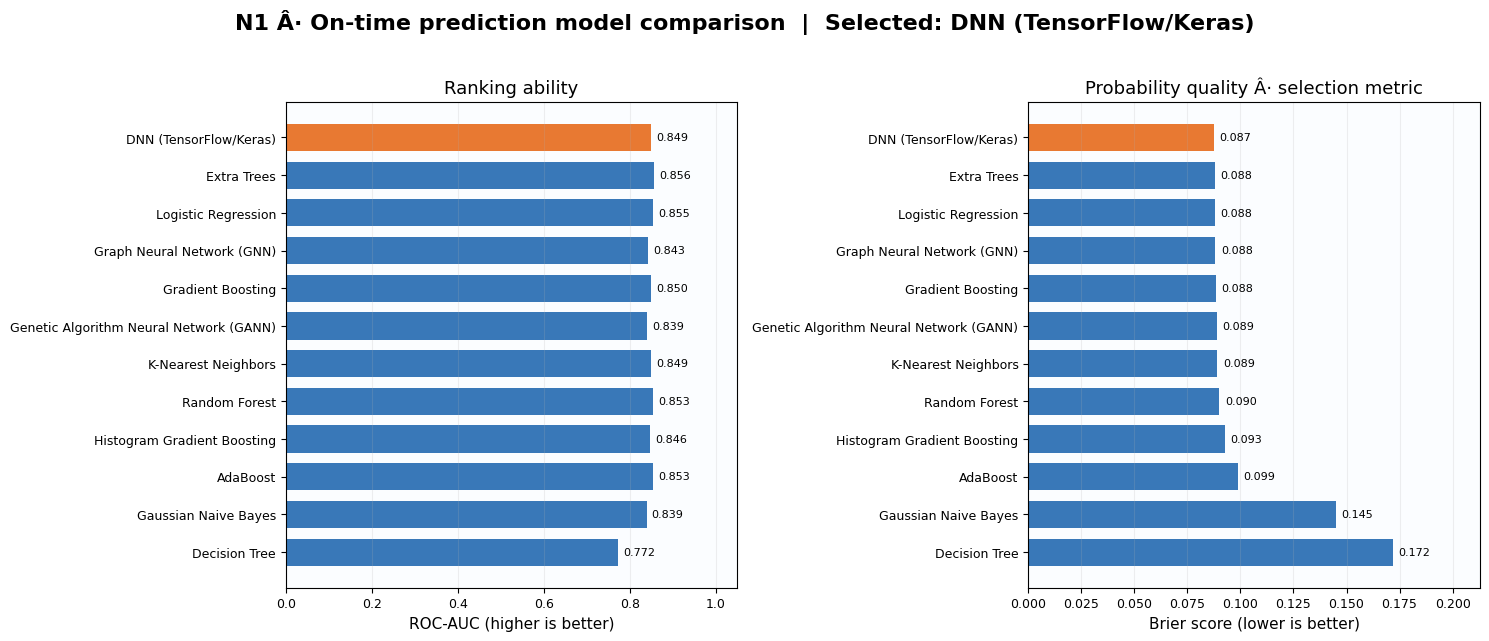

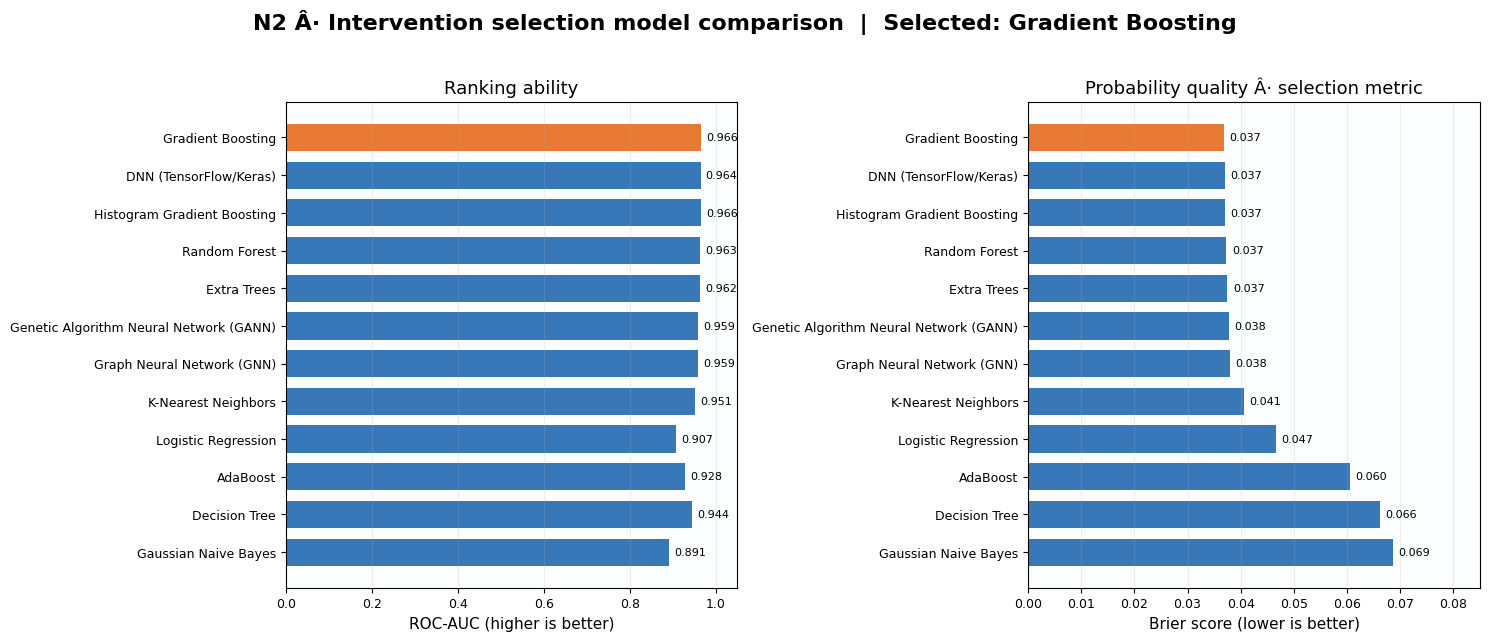

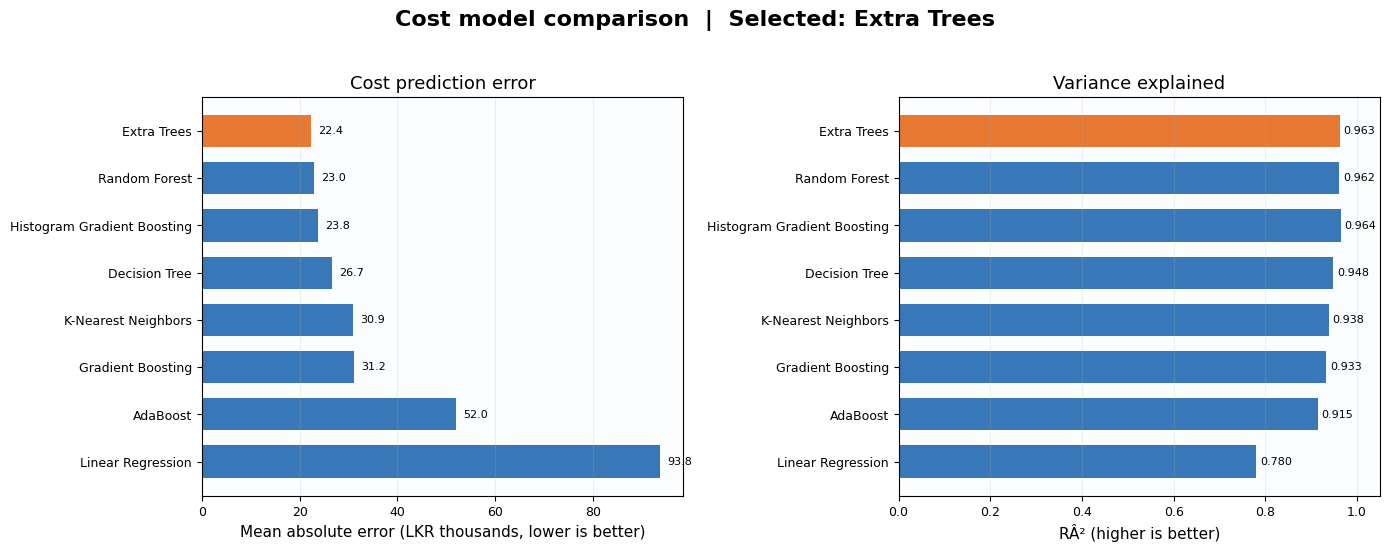

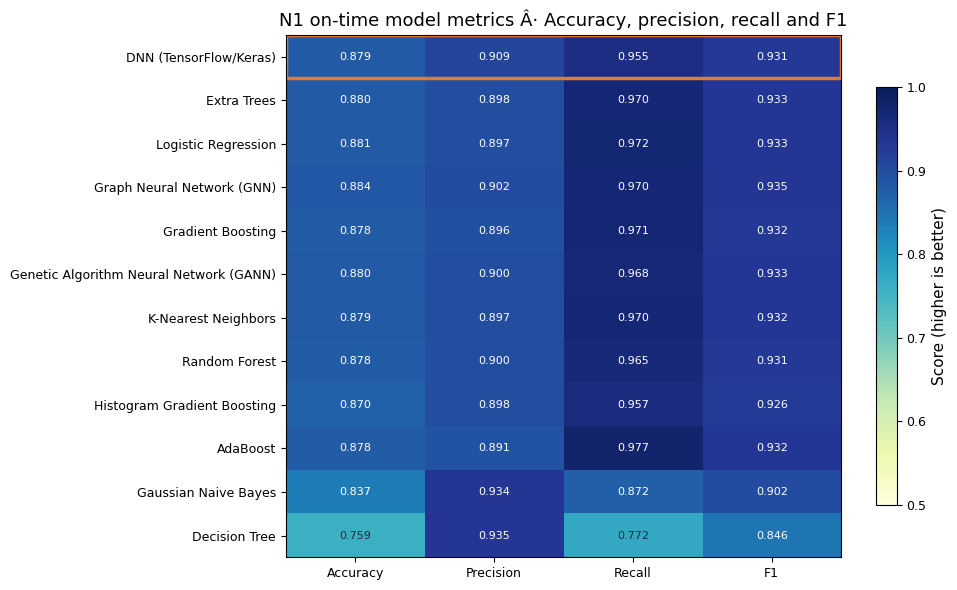

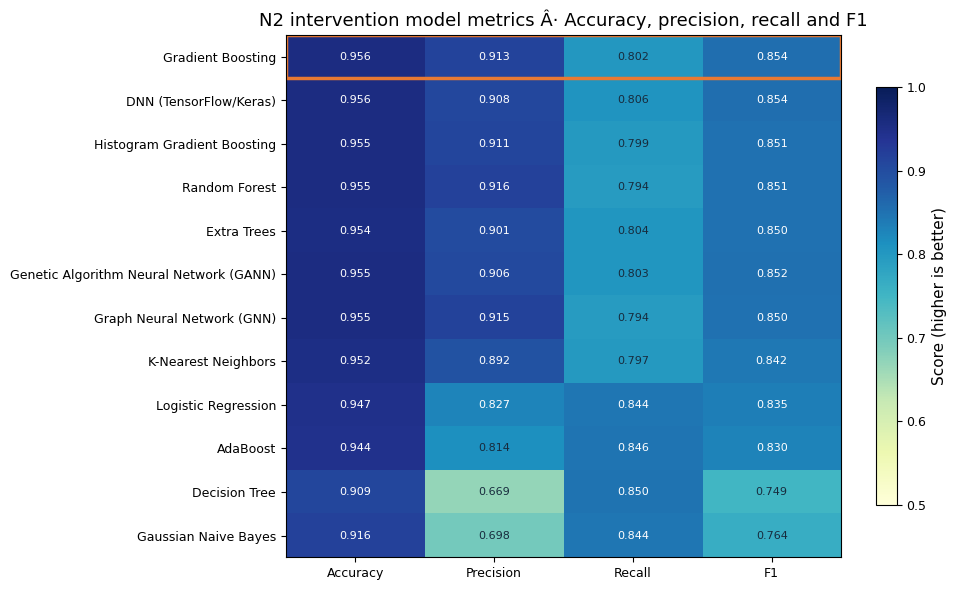

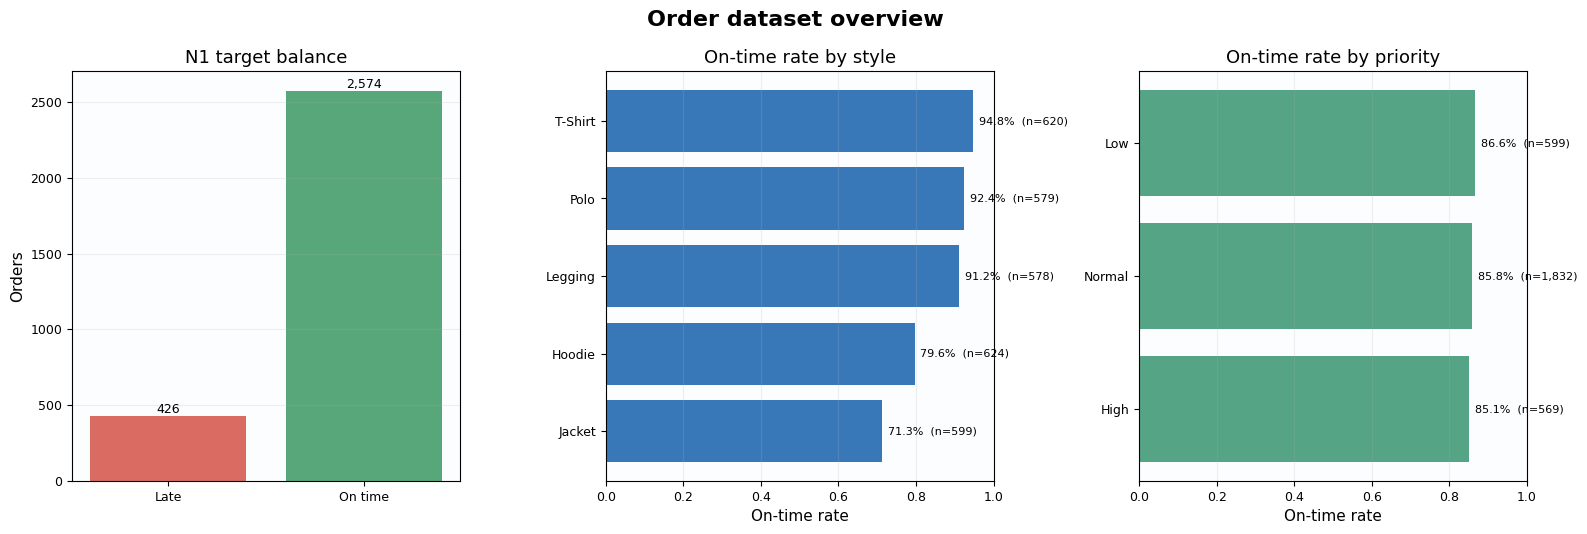

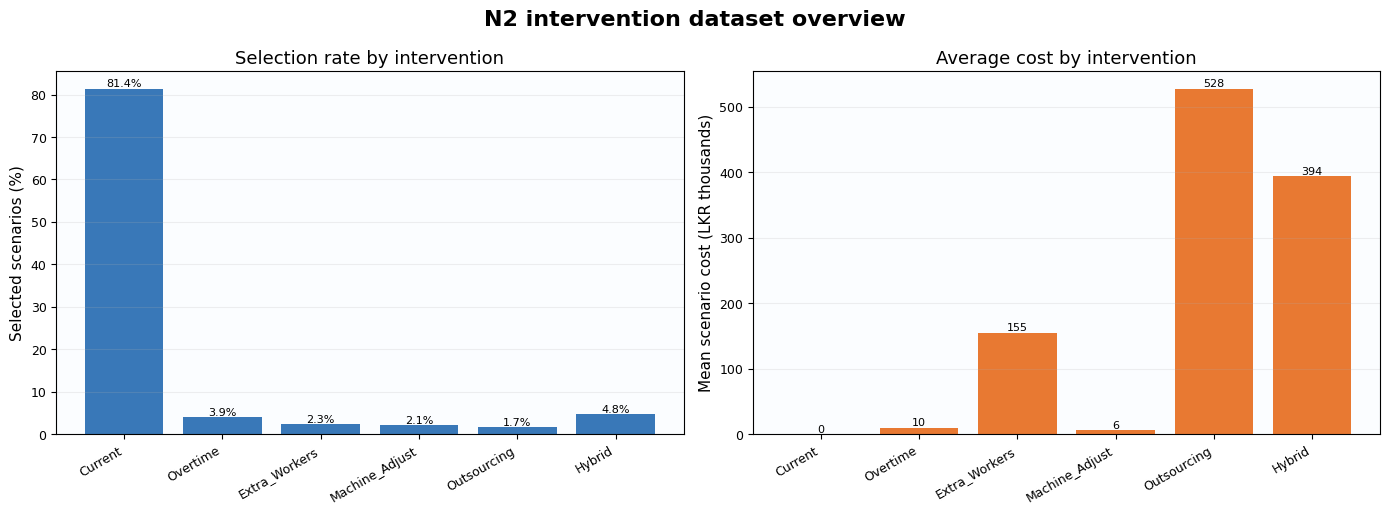

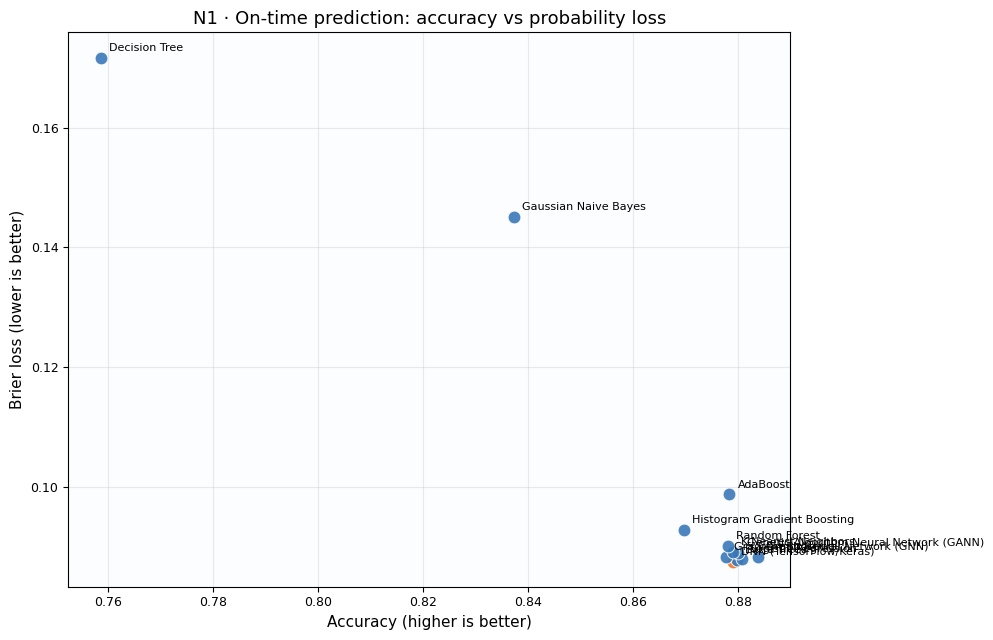

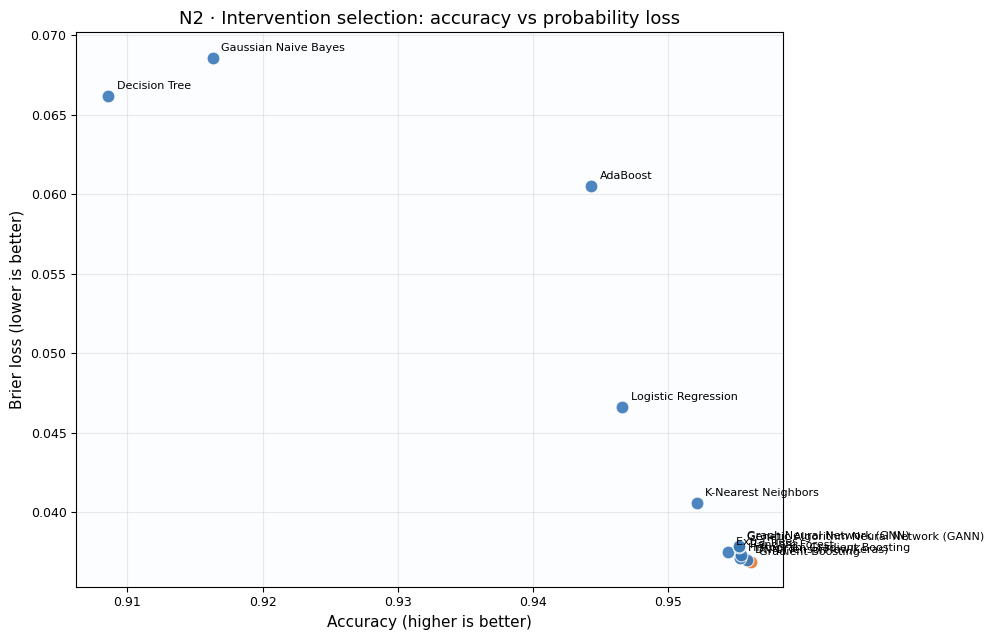

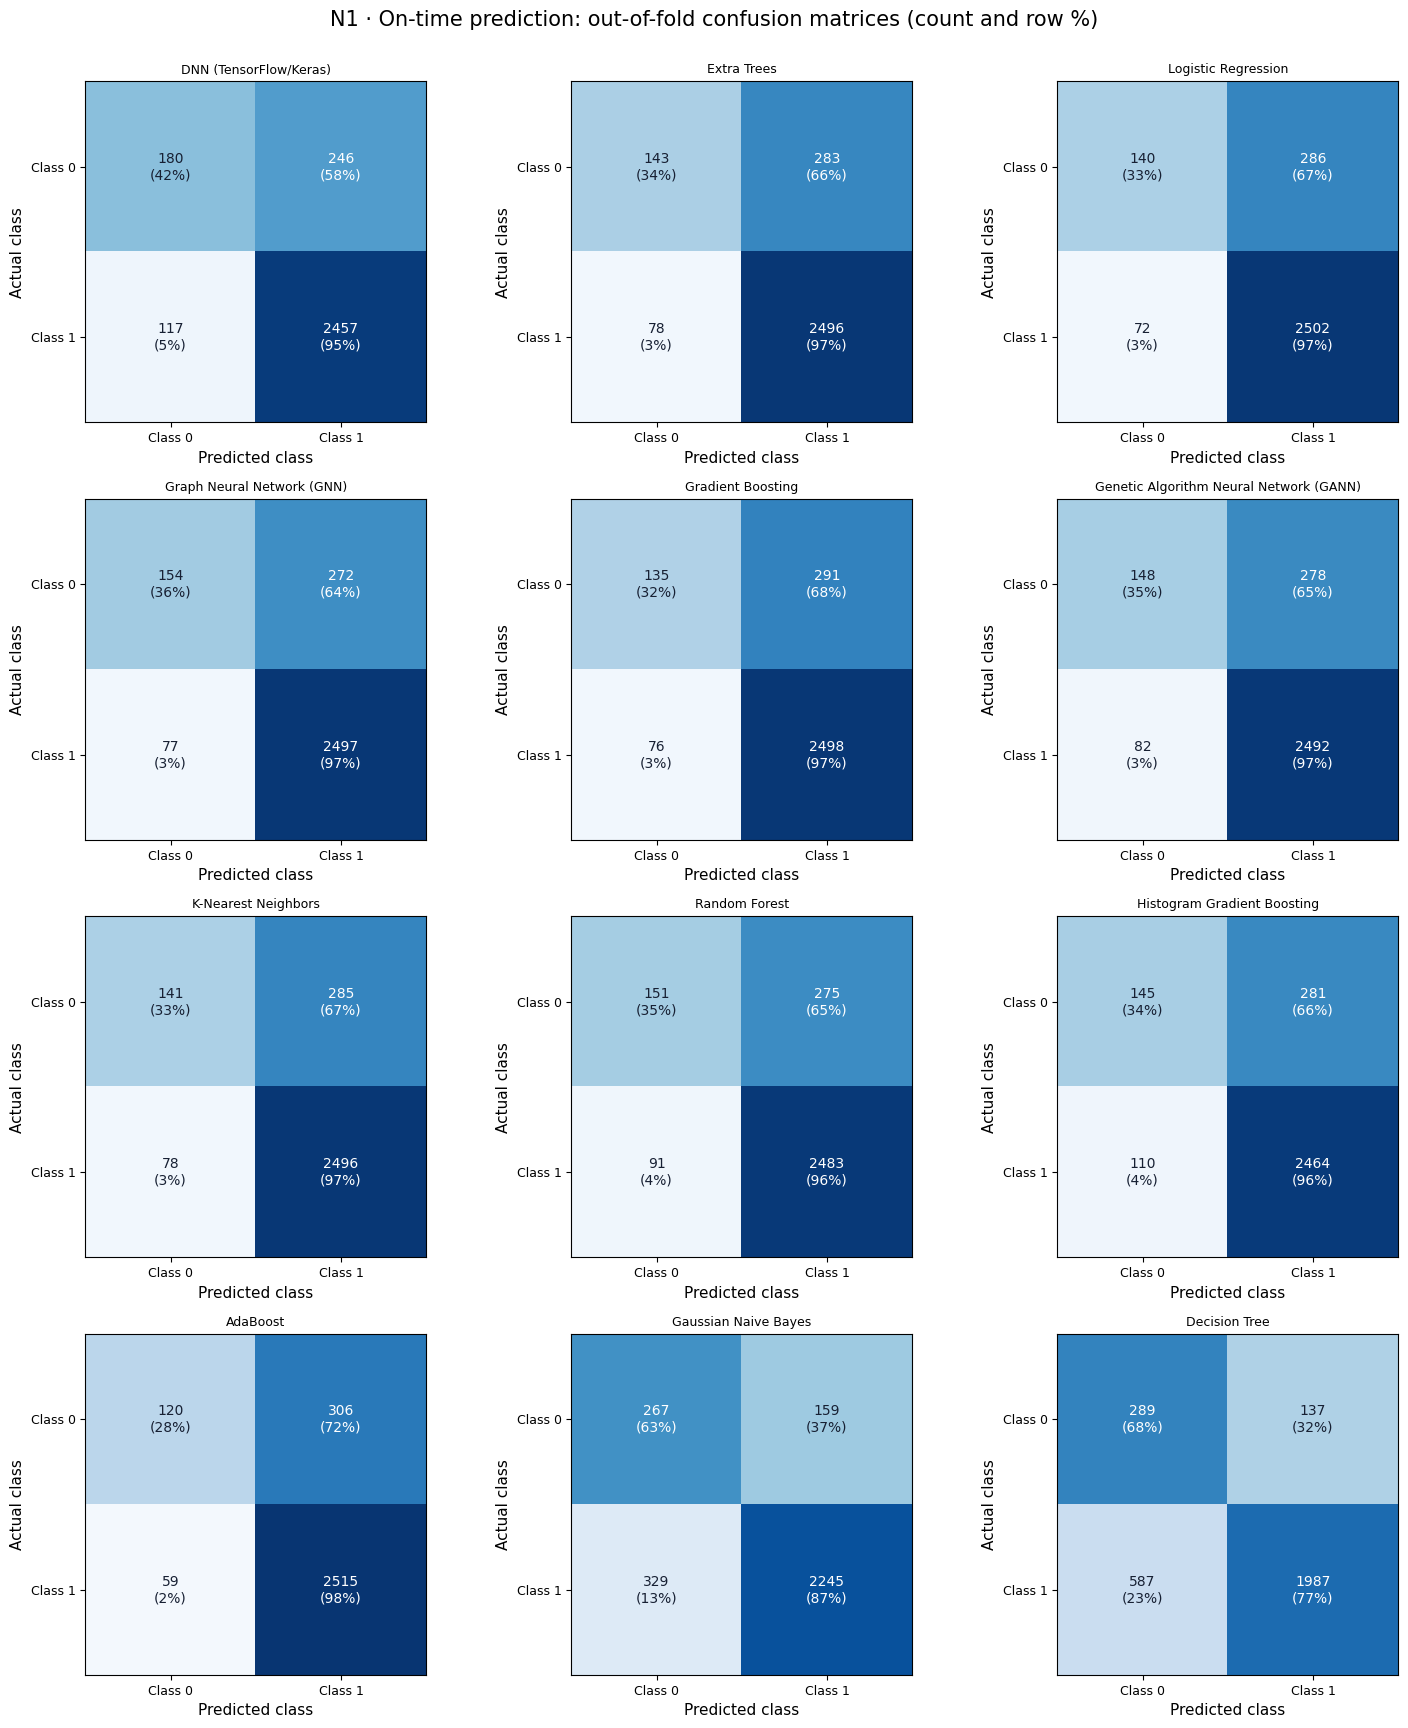

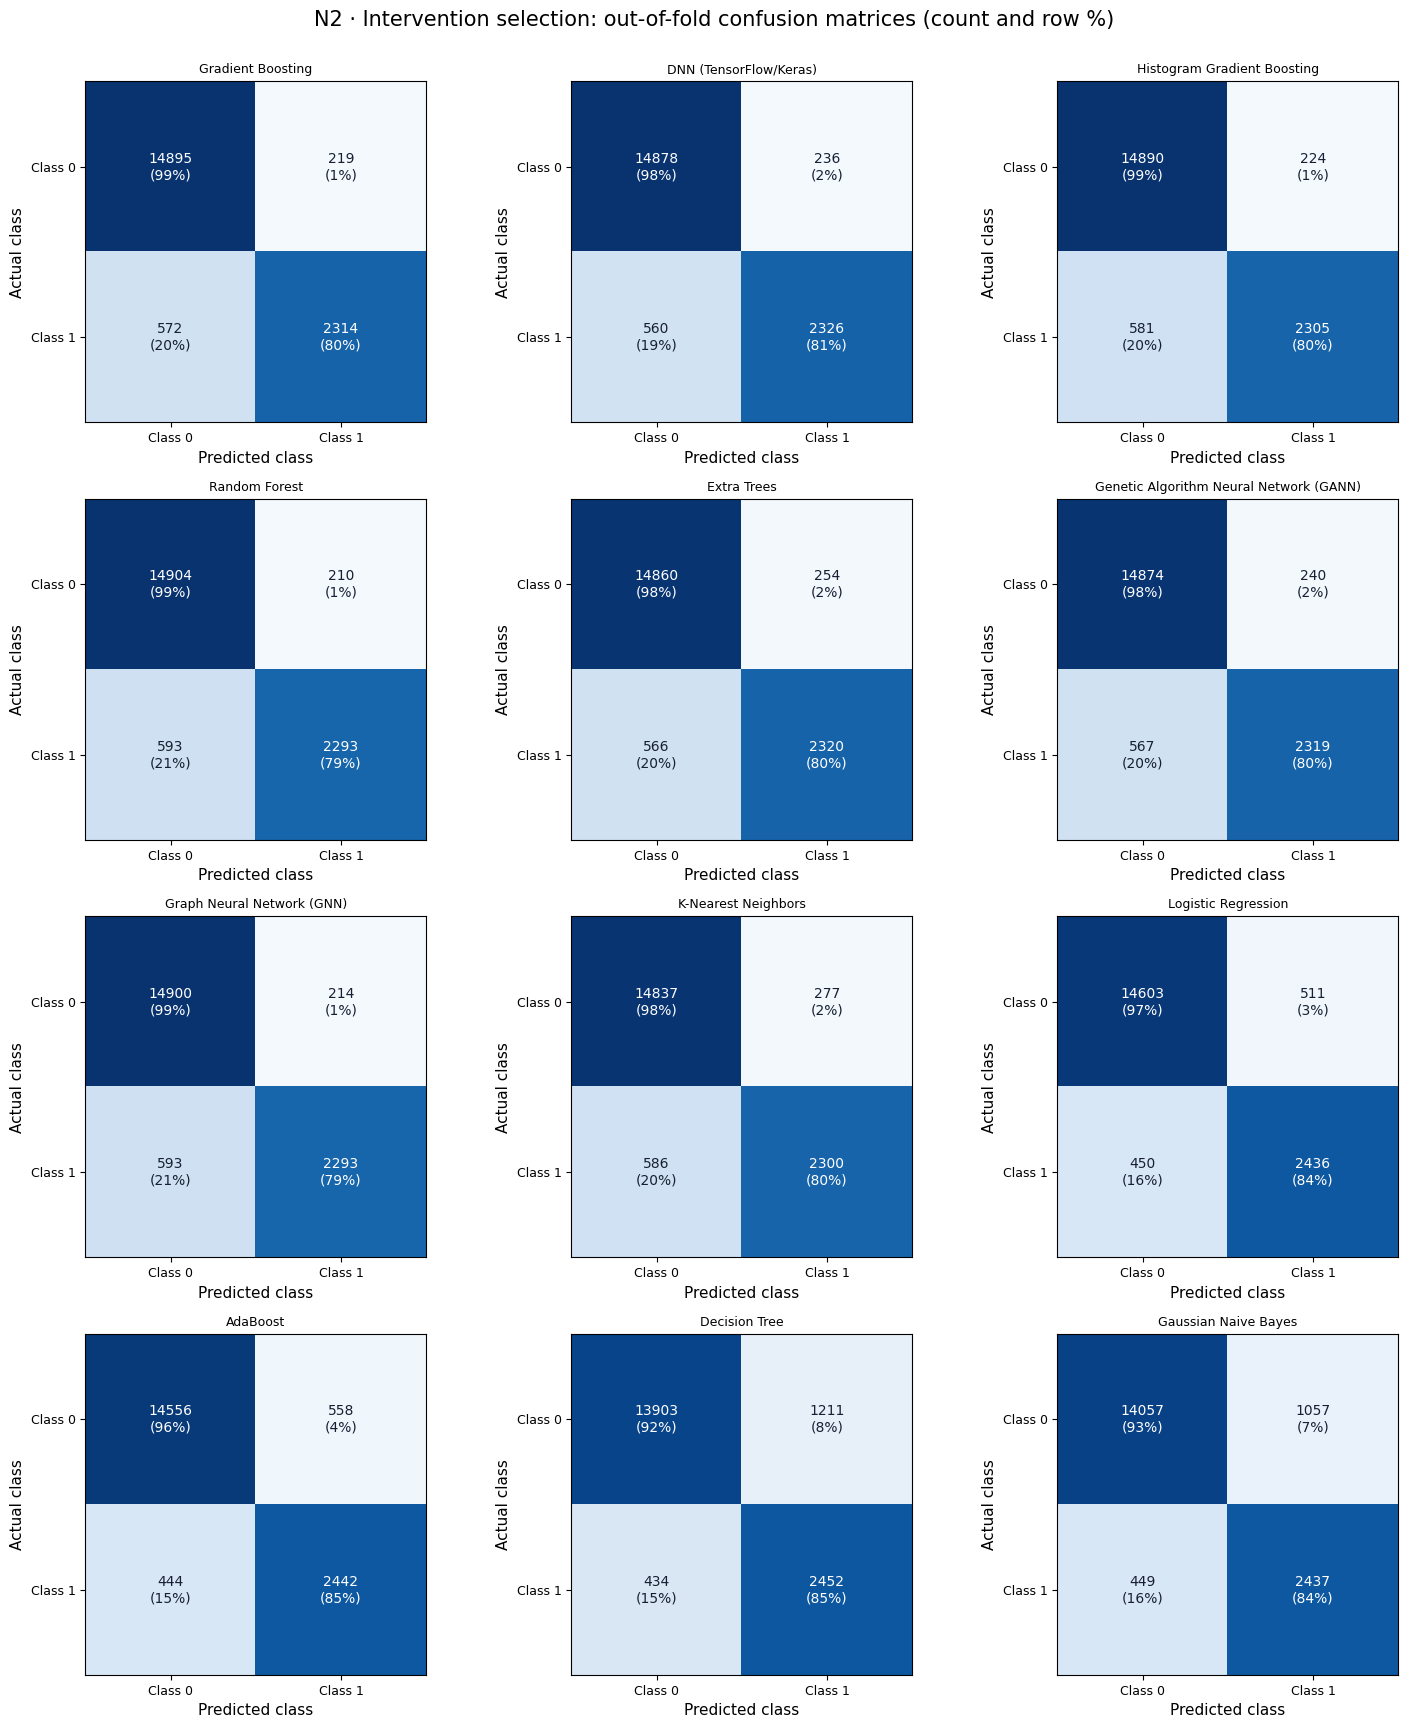

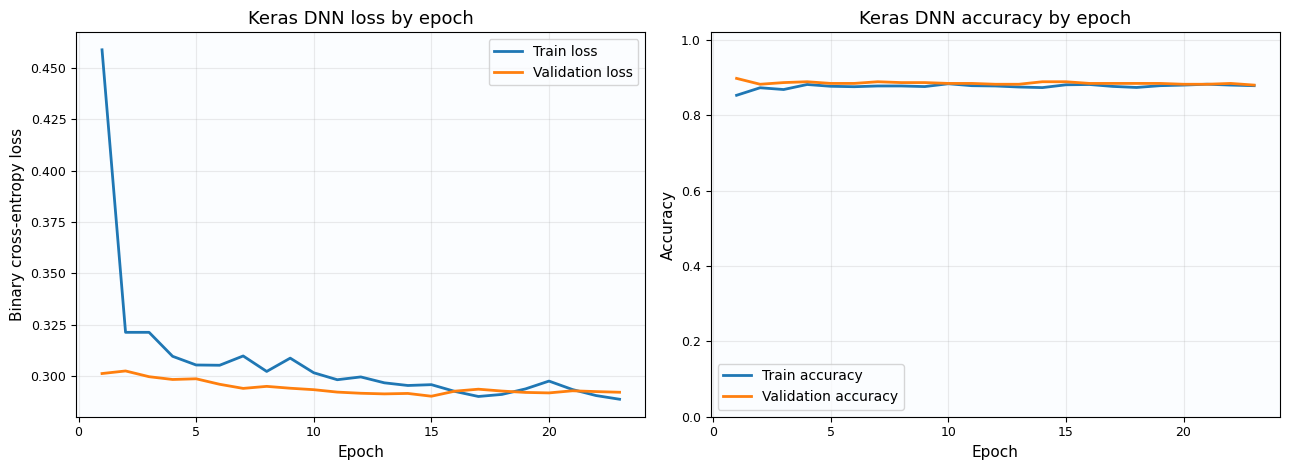

In [17]:
"""Create comparison charts from the saved cross-validation report."""
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
import pandas as pd
from matplotlib.patches import Rectangle



plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfdff",
})


def plot_classifier_comparison(prefix, title, best_name, scores):
    """Plot probability calibration and ranking scores for one target."""
    ranked = sorted(scores.items(), key=lambda item: item[1]["brier_score"])
    names = [item[0] for item in ranked]
    roc_auc = [item[1]["roc_auc"] for item in ranked]
    brier = [item[1]["brier_score"] for item in ranked]
    colors = ["#e87932" if name == best_name else "#3978b8" for name in names]
    y = np.arange(len(names))

    fig, axes = plt.subplots(1, 2, figsize=(15, max(6.4, len(names) * 0.48)))
    axes[0].barh(y, roc_auc, color=colors, height=0.72)
    axes[0].set_yticks(y, labels=names)
    axes[0].invert_yaxis()
    axes[0].set_xlim(0, 1.05)
    axes[0].set_xlabel("ROC-AUC (higher is better)")
    axes[0].set_title("Ranking ability")
    axes[0].grid(axis="x", alpha=0.2)
    for idx, value in enumerate(roc_auc):
        axes[0].text(value + 0.012, idx, f"{value:.3f}", va="center", fontsize=8)

    axes[1].barh(y, brier, color=colors, height=0.72)
    axes[1].set_yticks(y, labels=names)
    axes[1].invert_yaxis()
    axes[1].set_xlim(0, max(brier) * 1.24 if brier else 1)
    axes[1].set_xlabel("Brier score (lower is better)")
    axes[1].set_title("Probability quality Â· selection metric")
    axes[1].grid(axis="x", alpha=0.2)
    for idx, value in enumerate(brier):
        axes[1].text(value + max(brier) * 0.015, idx, f"{value:.3f}", va="center", fontsize=8)

    fig.suptitle(f"{title} model comparison  |  Selected: {best_name}",
                 fontsize=16, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    display(fig)
    plt.close(fig)


plot_classifier_comparison("n1", "N1 Â· On-time prediction",
                           report["N1_best"], report["N1_models"])
plot_classifier_comparison("n2", "N2 Â· Intervention selection",
                           report["N2_best"], report["N2_models"])

cost_ranked = sorted(report["cost_models"].items(), key=lambda item: item[1]["mae"])
cost_names = [item[0] for item in cost_ranked]
mae = [item[1]["mae"] / 1000 for item in cost_ranked]
r2 = [item[1]["r2"] for item in cost_ranked]
cost_colors = ["#e87932" if name == report["cost_best"] else "#3978b8"
               for name in cost_names]
y = np.arange(len(cost_names))
fig, axes = plt.subplots(1, 2, figsize=(14, max(5.5, len(cost_names) * 0.62)))
axes[0].barh(y, mae, color=cost_colors, height=0.68)
axes[0].set_yticks(y, labels=cost_names)
axes[0].invert_yaxis()
axes[0].set_xlabel("Mean absolute error (LKR thousands, lower is better)")
axes[0].set_title("Cost prediction error")
axes[0].grid(axis="x", alpha=0.2)
for idx, value in enumerate(mae):
    axes[0].text(value + max(mae) * 0.015, idx, f"{value:.1f}", va="center", fontsize=8)

axes[1].barh(y, r2, color=cost_colors, height=0.68)
axes[1].set_yticks(y, labels=cost_names)
axes[1].invert_yaxis()
axes[1].set_xlim(min(0, min(r2) - 0.05), 1.05)
axes[1].set_xlabel("RÂ² (higher is better)")
axes[1].set_title("Variance explained")
axes[1].grid(axis="x", alpha=0.2)
for idx, value in enumerate(r2):
    axes[1].text(value + 0.008, idx, f"{value:.3f}", va="center", fontsize=8)

fig.suptitle(f"Cost model comparison  |  Selected: {report['cost_best']}",
             fontsize=16, fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))
display(fig)
plt.close(fig)

def plot_classification_metric_heatmap(prefix, title, best_name, scores):
    """Summarize threshold-based classification metrics across all candidates."""
    metric_names = ["accuracy", "precision", "recall", "f1"]
    ranked = sorted(scores.items(), key=lambda item: item[1]["brier_score"])
    names = [item[0] for item in ranked]
    values = np.array([[item[1][metric] for metric in metric_names]
                       for item in ranked])
    fig, ax = plt.subplots(figsize=(10, max(6, len(names) * 0.46)))
    image = ax.imshow(values, cmap="YlGnBu", vmin=0.5, vmax=1.0, aspect="auto")
    ax.set_xticks(np.arange(len(metric_names)), labels=[m.title() for m in metric_names])
    ax.set_yticks(np.arange(len(names)), labels=names)
    ax.set_title(f"{title} Â· Accuracy, precision, recall and F1")
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, f"{values[row, column]:.3f}",
                    ha="center", va="center", fontsize=8,
                    color="white" if values[row, column] >= 0.82 else "#172b3d")
    best_row = names.index(best_name)
    ax.add_patch(Rectangle((-0.5, best_row - 0.5), len(metric_names), 1,
                           fill=False, edgecolor="#e87932", linewidth=2.5))
    fig.colorbar(image, ax=ax, label="Score (higher is better)", shrink=0.8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


plot_classification_metric_heatmap("n1", "N1 on-time model metrics",
                                   report["N1_best"], report["N1_models"])
plot_classification_metric_heatmap("n2", "N2 intervention model metrics",
                                   report["N2_best"], report["N2_models"])

# Descriptive plots use the same source CSV records as the training pipeline.
orders = pd.read_csv(os.path.join("data", "orders.csv"))
interventions = pd.read_csv(os.path.join("data", "interventions.csv"))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))

class_counts = orders["on_time_flag"].value_counts().reindex([0, 1], fill_value=0)
axes[0].bar(["Late", "On time"], class_counts.values,
            color=["#d96b62", "#58a77b"])
axes[0].set_title("N1 target balance")
axes[0].set_ylabel("Orders")
axes[0].grid(axis="y", alpha=0.2)
for idx, count in enumerate(class_counts.values):
    axes[0].text(idx, count, f"{count:,}", ha="center", va="bottom", fontsize=9)

style_summary = orders.groupby("style_id")["on_time_flag"].agg(["mean", "count"])
style_summary = style_summary.sort_values("mean")
axes[1].barh(style_summary.index.astype(str), style_summary["mean"], color="#3978b8")
axes[1].set_xlim(0, 1)
axes[1].set_title("On-time rate by style")
axes[1].set_xlabel("On-time rate")
axes[1].grid(axis="x", alpha=0.2)
for idx, value in enumerate(style_summary["mean"]):
    axes[1].text(value + 0.015, idx, f"{value:.1%}  (n={style_summary['count'].iloc[idx]:,})",
                 va="center", fontsize=8)

priority_summary = orders.groupby("priority")["on_time_flag"].agg(["mean", "count"])
priority_summary = priority_summary.sort_values("mean")
axes[2].barh(priority_summary.index.astype(str), priority_summary["mean"], color="#55a486")
axes[2].set_xlim(0, 1)
axes[2].set_title("On-time rate by priority")
axes[2].set_xlabel("On-time rate")
axes[2].grid(axis="x", alpha=0.2)
for idx, value in enumerate(priority_summary["mean"]):
    axes[2].text(value + 0.015, idx, f"{value:.1%}  (n={priority_summary['count'].iloc[idx]:,})",
                 va="center", fontsize=8)

fig.suptitle("Order dataset overview", fontsize=16, fontweight="bold")
fig.tight_layout()
display(fig)
plt.close(fig)

scenario_order = ["Current", "Overtime", "Extra_Workers", "Machine_Adjust",
                  "Outsourcing", "Hybrid"]
scenario_summary = interventions.groupby("scenario_type").agg(
    selection_rate=("selected_flag", "mean"),
    mean_cost=("total_cost", "mean"),
    count=("scenario_id", "count"),
)
scenario_summary = scenario_summary.reindex(
    [scenario for scenario in scenario_order if scenario in scenario_summary.index]
)
x = np.arange(len(scenario_summary))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].bar(x, scenario_summary["selection_rate"] * 100, color="#3978b8")
axes[0].set_xticks(x, labels=scenario_summary.index, rotation=30, ha="right")
axes[0].set_ylabel("Selected scenarios (%)")
axes[0].set_title("Selection rate by intervention")
axes[0].grid(axis="y", alpha=0.2)
for idx, value in enumerate(scenario_summary["selection_rate"] * 100):
    axes[0].text(idx, value, f"{value:.1f}%", ha="center", va="bottom", fontsize=8)

mean_cost_k = scenario_summary["mean_cost"] / 1000
axes[1].bar(x, mean_cost_k, color="#e87932")
axes[1].set_xticks(x, labels=scenario_summary.index, rotation=30, ha="right")
axes[1].set_ylabel("Mean scenario cost (LKR thousands)")
axes[1].set_title("Average cost by intervention")
axes[1].grid(axis="y", alpha=0.2)
for idx, value in enumerate(mean_cost_k):
    axes[1].text(idx, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=8)

fig.suptitle("N2 intervention dataset overview", fontsize=16, fontweight="bold")
fig.tight_layout()
display(fig)
plt.close(fig)



# Accuracy vs probability loss: every point is a model; orange marks the selected model.
def plot_accuracy_vs_loss(title, best_name, scores):
    names = list(scores)
    accuracy = [scores[name]["accuracy"] for name in names]
    loss = [scores[name]["brier_score"] for name in names]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    for name, x, y_value in zip(names, accuracy, loss):
        color = "#e87932" if name == best_name else "#3978b8"
        ax.scatter(x, y_value, s=85, color=color, alpha=0.9, edgecolor="white", linewidth=0.7)
        ax.annotate(name, (x, y_value), xytext=(6, 5), textcoords="offset points", fontsize=8)
    ax.set_xlabel("Accuracy (higher is better)")
    ax.set_ylabel("Brier loss (lower is better)")
    ax.set_title(f"{title}: accuracy vs probability loss")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


def plot_confusion_matrices(title, scores):
    names = list(scores)
    columns = 3
    rows = int(np.ceil(len(names) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 4.3 * rows), squeeze=False)
    for ax, name in zip(axes.flat, names):
        matrix = np.asarray(scores[name]["confusion_matrix"], dtype=int)
        row_totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float), where=row_totals != 0)
        ax.imshow(percentages, cmap="Blues", vmin=0, vmax=1)
        for row in range(2):
            for column in range(2):
                ax.text(column, row, f"{matrix[row, column]}\n({percentages[row, column]:.0%})",
                        ha="center", va="center", color="white" if percentages[row, column] > 0.55 else "#172033", fontsize=10)
        ax.set_xticks([0, 1], labels=["Class 0", "Class 1"])
        ax.set_yticks([0, 1], labels=["Class 0", "Class 1"])
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")
        ax.set_title(name, fontsize=9)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    fig.suptitle(f"{title}: out-of-fold confusion matrices (count and row %) ", fontsize=15, y=1.002)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


plot_accuracy_vs_loss("N1 · On-time prediction", report["N1_best"], report["N1_models"])
plot_accuracy_vs_loss("N2 · Intervention selection", report["N2_best"], report["N2_models"])
plot_confusion_matrices("N1 · On-time prediction", report["N1_models"])
plot_confusion_matrices("N2 · Intervention selection", report["N2_models"])

# DNN epoch curves use a dedicated train/validation split; comparison scores above use cross-validation.
history = dnn_history_model.history_
epochs = np.arange(1, len(history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(epochs, history["loss"], label="Train loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set_title("Keras DNN loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(epochs, history["accuracy"], label="Train accuracy", linewidth=2)
axes[1].plot(epochs, history["val_accuracy"], label="Validation accuracy", linewidth=2)
axes[1].set_title("Keras DNN accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.tight_layout()
display(fig)
plt.close(fig)

## Rankings and plots

In [18]:
import pandas as pd
from IPython.display import display

print(f"Training orders: {report['training_orders']:,}")
print(f"N1 selected model: {report['N1_best']}")
print(f"N2 selected model: {report['N2_best']}")
print(f"Cost selected model: {report['cost_best']}")
print(report["data_note"])

n1_table = pd.DataFrame(report["N1_models"]).T.drop(columns=["confusion_matrix"], errors="ignore").sort_values("brier_score")
n1_table.index.name = "N1 model"
display(n1_table.style.format("{:.4f}").highlight_min(subset=["brier_score"], color="#ffe3cc"))

n2_table = pd.DataFrame(report["N2_models"]).T.drop(columns=["confusion_matrix"], errors="ignore").sort_values("brier_score")
n2_table.index.name = "N2 model"
display(n2_table.style.format("{:.4f}").highlight_min(subset=["brier_score"], color="#ffe3cc"))

cost_table = pd.DataFrame(report["cost_models"]).T.sort_values("mae")
cost_table.index.name = "Cost model"
display(cost_table.style.format({"mae": "{:,.2f}", "r2": "{:.4f}"}).highlight_min(subset=["mae"], color="#ffe3cc"))

Training orders: 3,000
N1 selected model: DNN (TensorFlow/Keras)
N2 selected model: Gradient Boosting
Cost selected model: Extra Trees
Generated demo data; replace with real factory history for operational decisions.


,accuracy,precision,recall,f1,roc_auc,brier_score
N1 model,,,,,,
DNN (TensorFlow/Keras),0.8790,0.9090,0.9545,0.9312,0.8494,0.0875
Extra Trees,0.8797,0.8982,0.9697,0.9326,0.8555,0.0878
Logistic Regression,0.8807,0.8974,0.9720,0.9332,0.8545,0.0879
Graph Neural Network (GNN),0.8837,0.9018,0.9701,0.9347,0.8430,0.0882
Gradient Boosting,0.8777,0.8957,0.9705,0.9316,0.8498,0.0883
Genetic Algorithm Neural Network (GANN),0.8800,0.8996,0.9681,0.9326,0.8393,0.0890
K-Nearest Neighbors,0.8790,0.8975,0.9697,0.9322,0.8489,0.0891
Random Forest,0.8780,0.9003,0.9646,0.9314,0.8527,0.0901
Histogram Gradient Boosting,0.8697,0.8976,0.9573,0.9265,0.8459,0.0928


,accuracy,precision,recall,f1,roc_auc,brier_score
N2 model,,,,,,
Gradient Boosting,0.9561,0.9135,0.8018,0.8540,0.9656,0.0369
DNN (TensorFlow/Keras),0.9558,0.9079,0.8060,0.8539,0.9642,0.0370
Histogram Gradient Boosting,0.9553,0.9114,0.7987,0.8513,0.9658,0.0371
Random Forest,0.9554,0.9161,0.7945,0.8510,0.9634,0.0373
Extra Trees,0.9544,0.9013,0.8039,0.8498,0.9620,0.0375
Genetic Algorithm Neural Network (GANN),0.9552,0.9062,0.8035,0.8518,0.9585,0.0378
Graph Neural Network (GNN),0.9552,0.9146,0.7945,0.8504,0.9589,0.0379
K-Nearest Neighbors,0.9521,0.8925,0.7970,0.8420,0.9512,0.0406
Logistic Regression,0.9466,0.8266,0.8441,0.8352,0.9072,0.0466


,mae,r2
Cost model,,
Extra Trees,"22,364.94",0.9628
Random Forest,"22,998.29",0.9616
Histogram Gradient Boosting,"23,849.01",0.9640
Decision Tree,"26,680.34",0.9478
K-Nearest Neighbors,"30,922.95",0.9381
Gradient Boosting,"31,213.65",0.9331
AdaBoost,"52,013.36",0.9146
Linear Regression,"93,795.88",0.7805
